In [25]:
from functools import partial
import matplotlib.pyplot as plt
import numpy as np
from superfv import AdvectionSolver, ics

In [26]:
sim = AdvectionSolver(
    ic=partial(ics.square, rho_min=0.0, rho_max=1.0, vx=1.0),
    p=3,
    PAD_bounds={"rho": (0.0, 1.0)},
    use_global_bounds=True,
    use_SED=False,
    # use_ZS=True,
    # adaptive_dt=True,
    use_MOOD=True,
    rtol=0.0,
    fallback_cascade="muscl0",
    max_revs=3,
)

In [27]:
sim.run(1.0)

SuperFV: 81 steps | t=1.00e+00/1.00e+00, dt=1.55e-15 | rho_min=1.11e-07 | E_cons=nan | wall=9.66e-02s (done)


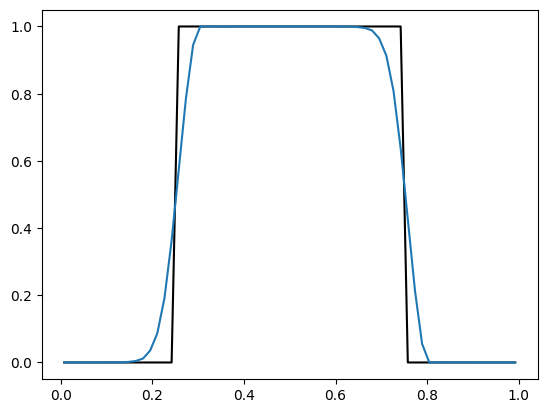

In [28]:
fig, ax = plt.subplots()
ax.plot(sim.mesh.centers[0], sim.snapshot_history[0].u[sim.idx("rho"), :, 0, 0], color='k')
ax.plot(sim.mesh.centers[0], sim.snapshot_history[-1].u[sim.idx("rho"), :, 0, 0])

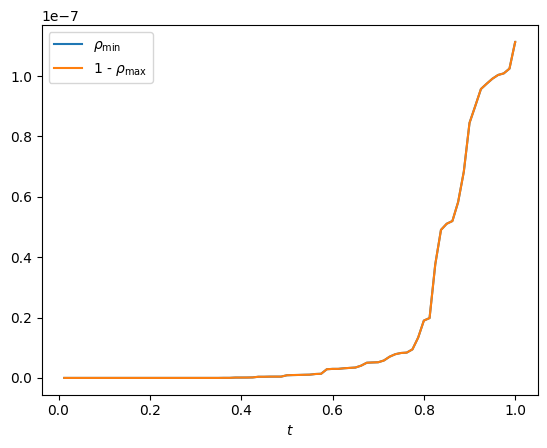

In [29]:
fig, ax = plt.subplots()

ax.set_xlabel(r"$t$")

ax.plot(sim.step_history.get_history("t_sim"), sim.step_history.get_history("rho_min"), label=r"$\rho_{\min}$")
ax.plot(sim.step_history.get_history("t_sim"), 1 - np.array(sim.step_history.get_history("rho_max")), label=r"1 - $\rho_{\max}$")

ax.legend()